# 07 · Upload → Muse Spark → optional SAM 3.1 → Muse Spark

Upload one plant photograph, ask Muse Spark to identify it, then optionally segment plant parts with Meta SAM 3.1 and send each resulting crop to Muse Spark. This is an interactive flow check, not a benchmark or a toxicity assessment.

Run top to bottom. The API key is read from Colab Secrets (`MODEL_API_KEY`) or the environment and is not written to disk. Your image is sent to Meta Model API when you run the Spark or SAM cells. Calls may incur charges.

SAM 3.1 segmentation is an optional section: skip it to use only Muse Spark. The default SAM text prompt is `flower`; change it to `plant` if the image is mostly foliage.

References: [Muse Spark image understanding](https://dev.meta.ai/docs/image-understanding), [SAM 3.1 overview](https://dev.meta.ai/docs/sam/overview), [SAM Python parser](https://dev.meta.ai/docs/sam/client-libraries).

## 1. Install the small API and image dependencies

This notebook uses the hosted Meta Model API for both models. It does not download model weights or require a GPU.

In [1]:
%pip -q install --upgrade openai Pillow matplotlib numpy meta-sam-parser

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.


## 2. Configure Meta API access and upload a photograph

In Colab, add `MODEL_API_KEY` under **Secrets** and grant this notebook access. You can also set that environment variable manually in a private runtime. The upload widget accepts one image.

Saving vecteezy_a-flower-shop-with-many-different-flowers_55963736.jpeg to vecteezy_a-flower-shop-with-many-different-flowers_55963736.jpeg
Loaded vecteezy_a-flower-shop-with-many-different-flowers_55963736.jpeg: 3264 × 5824


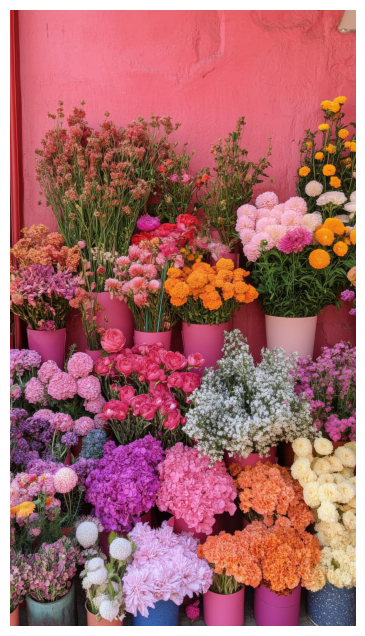

In [14]:
import base64
import io
import json
import os
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps
from openai import AsyncOpenAI, OpenAI

try:
    from google.colab import files, userdata
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError(f"Upload exactly one image; received {len(uploaded)} files.")
    image_name, image_bytes = next(iter(uploaded.items()))
    try:
        MODEL_API_KEY = userdata.get("MODEL_API_KEY")
    except Exception:
        MODEL_API_KEY = None
except ImportError:
    image_path = Path(input("Path to an image file: ")).expanduser()
    image_name = image_path.name
    image_bytes = image_path.read_bytes()
    MODEL_API_KEY = os.environ.get("MODEL_API_KEY")

if not MODEL_API_KEY:
    MODEL_API_KEY = os.environ.get("MODEL_API_KEY") or getpass("Meta Model API key: ")
if not MODEL_API_KEY.strip():
    raise ValueError("A Meta Model API key is required to call Muse Spark or SAM.")

image = ImageOps.exif_transpose(Image.open(io.BytesIO(image_bytes))).convert("RGB")
if image.width < 2 or image.height < 2:
    raise ValueError(f"Image dimensions are too small: {image.size}")

MODEL_API_BASE = "https://api.meta.ai/v1"
SPARK_MODEL = "muse-spark-1.3"
SAM_MODEL = "sam-3.1"
spark_client = OpenAI(base_url=MODEL_API_BASE, api_key=MODEL_API_KEY, timeout=120.0, max_retries=2)
sam_client = AsyncOpenAI(base_url=MODEL_API_BASE, api_key=MODEL_API_KEY, timeout=180.0, max_retries=2)

def to_png_bytes(pil_image):
    buffer = io.BytesIO()
    pil_image.save(buffer, format="PNG")
    return buffer.getvalue()

def image_data_url(image_content, mime_type="image/png"):
    return f"data:{mime_type};base64," + base64.b64encode(image_content).decode("ascii")

print(f"Loaded {image_name}: {image.width} × {image.height}")
plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off");

Resized image to half dimensions: 1632 × 2912


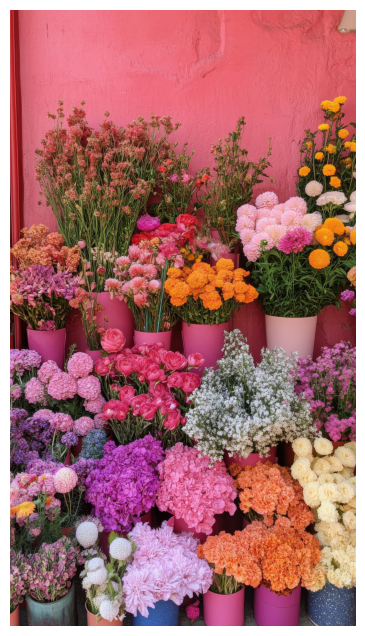

In [15]:
new_size = (image.width // 2, image.height // 2)
image = image.resize(new_size, Image.Resampling.LANCZOS)
image_bytes = to_png_bytes(image)
original_data_url = image_data_url(image_bytes, "image/png")

print(f"Resized image to half dimensions: {image.width} × {image.height}")
plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off");

## 3. Ask Muse Spark about the original image

Muse Spark returns schema-constrained JSON so the fields can be parsed directly. It estimates how many individual flowers are visible and recommends whether segmentation may help. Treat the count and recommendation as a visual estimate; you decide whether to run the optional SAM section. This is not a toxicity assessment.

In [17]:
CONFIDENCE = {
    "type": "string",
    "enum": ["high", "medium", "low"]
}

CONFIDENCE_SCHEMA = {
    "type": "string",
    "enum": ["high", "medium", "low"]
}

CONFIDENCE_SCHEMA = {
    "type": "string",
    "enum": ["high", "medium", "low"]
}

PLANT_ASSESSMENT_FORMAT = {
    "type": "json_schema",
    "json_schema": {
        "name": "plant_image_assessment",
        "strict": True,
        "schema": {
            "type": "object",
            "additionalProperties": False,
            "properties": {
                "is_bouquet": {
                    "type": "boolean",
                    "description": (
                        "Whether the image contains an arranged collection "
                        "of cut flowers, typically gathered together or in a vase."
                    )
                },
                "bouquet_type": {
                    "type": "string",
                    "enum": [
                        "single_species",
                        "mixed_species",
                        "uncertain",
                        "not_bouquet"
                    ],
                    "description": (
                        "Whether a bouquet contains one or multiple visually "
                        "distinct plant types. Use not_bouquet when is_bouquet "
                        "is false."
                    )
                },
                "distinct_plant_count": {
                    "type": "integer",
                    "description": (
                        "Number of visually distinct plant types detected. "
                        "Multiple flowers belonging to the same apparent "
                        "plant type count as one. Include distinct unidentified "
                        "plant types when visually distinguishable."
                    )
                },
                "plant_groups": {
                    "type": "array",
                    "description": (
                        "One entry per visually distinct plant type. "
                        "Multiple flowers of the same apparent type belong "
                        "to one group. Include unidentified plant types."
                    ),
                    "items": {
                        "type": "object",
                        "additionalProperties": False,
                        "properties": {
                            "id": {
                                "type": "integer",
                                "description": "Unique group ID starting at 1."
                            },
                            "plant_identification": {
                                "type": "string",
                                "description": (
                                    "Most likely common plant name, "
                                    "or Unknown."
                                )
                            },
                            "scientific_name": {
                                "type": "string",
                                "description": (
                                    "Most likely scientific name at species "
                                    "or genus level, or Unknown."
                                )
                            },
                            "toxicity_lookup_key": {
                                "type": "string",
                                "description": (
                                    "Candidate normalized key for the toxicity "
                                    "database, or unknown when no reliable "
                                    "match exists."
                                )
                            },
                            "identification_confidence": CONFIDENCE_SCHEMA,
                            "location_description": {
                                "type": "string",
                                "description": (
                                    "Location of this plant group in the image, "
                                    "such as left, center, right, foreground, "
                                    "or behind another plant."
                                )
                            },
                            "visual_evidence": {
                                "type": "array",
                                "items": {
                                    "type": "string"
                                },
                                "description": (
                                    "Visible characteristics supporting "
                                    "the proposed identification."
                                )
                            },
                            "needs_inspection": {
                                "type": "boolean",
                                "description": (
                                    "Whether closer inspection could improve "
                                    "identification of this plant group."
                                )
                            }
                        },
                        "required": [
                            "id",
                            "plant_identification",
                            "scientific_name",
                            "toxicity_lookup_key",
                            "identification_confidence",
                            "location_description",
                            "visual_evidence",
                            "needs_inspection"
                        ]
                    }
                },
                "suggest_segmentation": {
                    "type": "boolean",
                    "description": (
                        "Whether segmentation could improve identification "
                        "by isolating overlapping, uncertain, or visually "
                        "distinct plant regions."
                    )
                },
                "segmentation_reason": {
                    "type": "string",
                    "description": (
                        "Brief explanation of why segmentation would "
                        "or would not help."
                    )
                },
                "another_photo_needed": {
                    "type": "boolean",
                    "description": (
                        "Whether another photograph would materially "
                        "improve identification."
                    )
                },
                "photo_instructions": {
                    "type": "string",
                    "description": (
                        "Specific instructions for the most useful next "
                        "photograph. Empty string if unnecessary."
                    )
                },
                "photo_reason": {
                    "type": "string",
                    "description": (
                        "Why the additional photograph would help. "
                        "Empty string if unnecessary."
                    )
                }
            },
            "required": [
                "is_bouquet",
                "bouquet_type",
                "distinct_plant_count",
                "plant_groups",
                "suggest_segmentation",
                "segmentation_reason",
                "another_photo_needed",
                "photo_instructions",
                "photo_reason"
            ]
        }
    }
}

PLANT_ASSESSMENT_PROMPT = """
You are a visual plant investigation assistant.

Analyze the provided photograph to identify visually distinct
plant types, determine whether segmentation would improve
identification, and decide whether another photograph is needed.

BOUQUET DETECTION

- Determine whether the photograph contains a bouquet of cut flowers.
- A bouquet may contain one or multiple plant species.
- Do not classify potted plants or naturally growing flower
  clusters as bouquets.
- Set bouquet_type to single_species, mixed_species, or uncertain.
- Use not_bouquet when is_bouquet is false.
- Do not assume all flowers in a bouquet belong to one species.

DISTINCT PLANT DETECTION

- Identify every visually distinct plant type in the photograph.
- Count distinct plant types, NOT individual flowers, leaves,
  stems, or blossoms.
- Multiple flowers belonging to the same apparent plant type
  count as ONE group.
- Several visually identical plants may belong to one group.
- Separate visually different plant types into different groups.
- Include distinct unidentified plant types as Unknown.
- Do not count different parts of the same plant as separate types.
- Do not invent plants hidden behind visible objects.
- Set distinct_plant_count equal to the number of plant_groups.
- Use 0 and an empty plant_groups array when no plants are visible.

PLANT IDENTIFICATION

For each visually distinct plant group:

- Provide the most likely common name.
- Provide the scientific name when supported by visual evidence.
- Prefer genus-level identification when species is uncertain.
- Use Unknown when identification is unreliable.
- Describe distinguishing visible features.
- Describe where the group appears in the photograph.
- Assign qualitative identification confidence: high, medium, or low.
- Set needs_inspection when further examination could
  materially improve identification.

Do not merge different plant species merely because they
have similar colors or appear in the same arrangement.

Do not invent confidence percentages.

TOXICITY DATABASE MATCHING

- Propose a toxicity_lookup_key for each plant group.
- Match the identified taxon to an allowed database key.
- Use unknown when no reliable matching key exists.
- Do not substitute a different plant to obtain a database match.
- Do not infer toxicity or pet safety.
- Do not provide veterinary or medical advice.
- The application independently verifies all database matches.

SEGMENTATION DECISION

Determine whether object segmentation would improve
identification or investigation.

Recommend segmentation when:

- Multiple visually distinct plant types overlap.
- Different species may be present but are difficult to separate.
- Background clutter interferes with identification.
- A plant region is partially obscured.
- An unidentified plant group requires closer inspection.
- Isolating individual regions could reveal useful
  identifying characteristics.

Do not recommend segmentation solely because several
flowers of the same plant type are visible.

Segmentation cannot recover details hidden from the camera.

Explain briefly why segmentation would or would not help.

ADDITIONAL PHOTO DECISION

Determine whether another photograph would materially improve
plant identification.

Request another photograph when:

- Important identifying characteristics are missing.
- A plant is partially hidden.
- The image is blurry, dark, or too distant.
- Similar-looking species cannot be distinguished.
- Multiple plants cannot be reliably separated.
- Identification remains uncertain.

When requesting another photograph:

- Identify the specific plant or region requiring attention.
- Specify exactly what the user should photograph.
- Request the most useful angle or botanical feature.
- Prefer views showing flowers, leaves, stems, or the entire plant.
- Give clear, actionable instructions.
- Explain briefly why the requested photograph would help.
- Request only ONE additional photograph at a time.

Examples:

"Photograph the entire plant, including its leaves and stem."
"Take a close-up of the white flower on the left."
"Photograph where the leaves attach to the stem."
"Move closer to the unidentified plant behind the roses."
"Take a sharper photograph in natural daylight."

If another photograph is unnecessary:
- Set another_photo_needed to false.
- Return empty strings for photo_instructions and photo_reason.

IMPORTANT RULES

- Analyze only visible evidence.
- Never assume every plant has been identified.
- Unknown plant groups must remain unresolved.
- Do not infer toxicity or declare plants safe for pets.
- Identification confidence is qualitative, not calibrated.
- Return only valid JSON matching the provided schema.
"""

def ask_spark_for_assessment(data_url, extra_instruction=""):
    response = spark_client.chat.completions.create(
        model=SPARK_MODEL,
        messages=[{
            "role": "user",
            "content": [
                {"type": "text", "text": PLANT_ASSESSMENT_PROMPT + " " + extra_instruction},
                {"type": "image_url", "image_url": {"url": data_url}},
            ],
        }],
        response_format=PLANT_ASSESSMENT_FORMAT,
        max_completion_tokens=1284,
        reasoning_effort="minimal",
    )
    content = response.choices[0].message.content
    if not content:
        raise ValueError("Muse Spark returned an empty assessment.")
    return json.loads(content)

original_data_url = image_data_url(
    image_bytes,
    Image.open(io.BytesIO(image_bytes)).get_format_mimetype() or "image/png",
)
spark_assessment = ask_spark_for_assessment(original_data_url)
print(json.dumps(spark_assessment, indent=2, ensure_ascii=False))
print("\nSegmentation suggestion:", "Run SAM if useful" if spark_assessment["suggest_segmentation"] else "Probably optional")

{
  "another_photo_needed": true,
  "bouquet_type": "mixed_species",
  "distinct_plant_count": 7,
  "is_bouquet": true,
  "photo_instructions": "Move closer and photograph the central pink ruffled flowers and the orange pom-pom flowers in natural daylight, showing flowers, leaves and stems.",
  "photo_reason": "Many distinct types overlap at a distance and key leaf and flower details are missing, preventing reliable separation of similar-looking species.",
  "plant_groups": [
    {
      "id": 1,
      "identification_confidence": "medium",
      "location_description": "center-right and right side, orange and yellow pom-pom clusters in pink buckets",
      "needs_inspection": true,
      "plant_identification": "Marigold",
      "scientific_name": "Tagetes erecta",
      "toxicity_lookup_key": "tagetes_erecta",
      "visual_evidence": [
        "dense orange-yellow pom-pom flower heads",
        "compact ruffled petals",
        "upright stems with green foliage"
      ]
    },
    {

## 4. Optional: segment flowers with SAM 3.1

Review `spark_assessment["suggest_segmentation"]` and its reason above. Run this section if you want to inspect the flower masks or test the segmented-image flow. SAM returns one mask per detected match for the short text prompt below. This can produce several flower masks, no masks, or imperfect masks. The parser dependency was installed in section 1.

In [18]:
from meta_sam_parser import (
    decode_mask_to_raster,
    image_segmentation_format,
    parse_responses_stream,
)

SAM_PROMPT = "flower"  # Try "plant" to target foliage and whole plants. or "flower" for flower heads
MAX_SEGMENTS = 6
MIN_MASK_PIXELS = 300

async def segment_uploaded_image(pil_image, prompt=SAM_PROMPT):
    content = to_png_bytes(pil_image)
    data_url = image_data_url(content, "image/png")
    events = await sam_client.responses.create(
        model=SAM_MODEL,
        input=[{
            "type": "message",
            "role": "user",
            "content": [
                {"type": "input_text", "text": prompt},
                {"type": "input_image", "image_url": data_url},
            ],
        }],
        stream=True,
        metadata={"mask_encoding": "one_bit"},
    )
    parsed = parse_responses_stream(events, image_segmentation_format())
    return await parsed.final_result()

segmentation = await segment_uploaded_image(image)
mask_records = [record for record in segmentation.records if hasattr(record, "mask")]
print(f"SAM returned {len(mask_records)} mask(s) for prompt {SAM_PROMPT!r}.")
if segmentation.diagnostics:
    print("Parser diagnostics:", segmentation.diagnostics)

segments = []
for record in mask_records:
    # SAM masks are local to their source-image bounds, so paste each decoded
    # raster back into a full-image canvas before displaying or cropping it.
    raster = np.frombuffer(decode_mask_to_raster(record.mask), dtype=np.uint8)
    local_mask = raster.reshape(record.mask.height, record.mask.width)
    bounds = record.bounds
    left = max(0, int(np.floor(bounds.left)))
    top = max(0, int(np.floor(bounds.top)))
    right = min(image.width, int(np.ceil(bounds.right)))
    bottom = min(image.height, int(np.ceil(bounds.bottom)))
    if right <= left or bottom <= top:
        continue
    local_image = Image.fromarray(local_mask * 255).resize(
        (right - left, bottom - top), resample=Image.Resampling.NEAREST
    )
    mask = np.zeros((image.height, image.width), dtype=bool)
    mask[top:bottom, left:right] = np.asarray(local_image) > 0
    ys, xs = np.where(mask)
    if len(xs) < MIN_MASK_PIXELS:
        continue
    left, right = int(xs.min()), int(xs.max()) + 1
    top, bottom = int(ys.min()), int(ys.max()) + 1
    # Keep a transparent background so Spark sees the segmented object clearly.
    rgba = np.zeros((image.height, image.width, 4), dtype=np.uint8)
    rgba[:, :, :3] = np.asarray(image)
    rgba[:, :, 3] = mask.astype(np.uint8) * 255
    crop = Image.fromarray(rgba).crop((left, top, right, bottom))
    segments.append({"object_id": getattr(record, "object_id", str(len(segments))),
                     "mask": mask, "box": (left, top, right, bottom), "crop": crop})

if not segments:
    print("No usable flower masks found. Try SAM_PROMPT = 'plant' or a clearer image.")
else:
    columns = min(3, len(segments))
    rows = (len(segments) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 5 * rows), squeeze=False)
    for ax, segment in zip(axes.flat, segments):
        overlay = np.asarray(image).copy()
        overlay[segment["mask"]] = (
            0.55 * overlay[segment["mask"]] + 0.45 * np.array([30, 220, 120])
        ).astype(np.uint8)
        ax.imshow(overlay)
        ax.set_title(f"SAM object {segment['object_id']} · box {segment['box']}")
        ax.axis("off")
    for ax in axes.flat[len(segments):]:
        ax.axis("off")
    plt.tight_layout()

Output hidden; open in https://colab.research.google.com to view.

## 5. Send each segmented crop to Muse Spark

This checks the end-to-end path: the original image went to Spark, SAM produced masks, and each cropped masked region now goes to Spark. A small number of segments keeps API usage manageable. Transparent pixels mark the area outside the mask.

In [10]:
if not segments:
    print("Run the SAM cell and inspect at least one mask before running this cell.")
else:
    segment_answers = []
    for index, segment in enumerate(segments[:MAX_SEGMENTS], start=1):
        crop_bytes = to_png_bytes(segment["crop"])
        crop_data_url = image_data_url(crop_bytes, "image/png")
        assessment = ask_spark_for_assessment(
            crop_data_url,
            extra_instruction=(
                "This image is a segmented crop from one detected region. The transparent "
                "background is outside the selected region. Estimate the number of visible "
                "flowers in this crop; keep uncertainty explicit."
            ),
        )
        segment_answers.append({"object_id": segment["object_id"], **assessment})
        print(f"Segment {index} (SAM object {segment['object_id']}):")
        print(json.dumps(assessment, indent=2, ensure_ascii=False))
        print()

    print(f"Sent {len(segment_answers)} of {len(segments)} usable segment(s) to Muse Spark.")

Segment 1 (SAM object 0):
{
  "another_photo_needed": false,
  "bouquet_type": "mixed_species",
  "distinct_plant_count": 4,
  "is_bouquet": true,
  "photo_instructions": "",
  "photo_reason": "",
  "plant_groups": [
    {
      "id": 1,
      "identification_confidence": "high",
      "location_description": "center foreground, large white open flower dominating crop",
      "needs_inspection": false,
      "plant_identification": "White Lily",
      "scientific_name": "Lilium",
      "toxicity_lookup_key": "unknown",
      "visual_evidence": [
        "large white 6-tepaled flower",
        "prominent brown anthers on green filaments",
        "central pistil with stigma",
        "one fully open bloom estimated"
      ]
    },
    {
      "id": 2,
      "identification_confidence": "medium",
      "location_description": "top right and left edges, partial pink blooms",
      "needs_inspection": false,
      "plant_identification": "Rose",
      "scientific_name": "Rosa",
      "toxi

## Interpretation and limitations

Compare Spark's response to the full image with its responses to individual SAM crops. A change in answer may reflect the crop, removed context, or an imperfect segmentation. SAM can miss blooms, include background, or split/merge objects. This notebook does not establish model accuracy, plant toxicity, or safety for pets. Verify plant identity and toxicity using authoritative botanical and veterinary references.

For a reproducible evaluation across examples, use the project's comparison notebooks and fixed manifests rather than this interactive upload flow.